In [ ]:
# Softmax
import numpy as np
arr = np.array([10, 1, 1.5, 1, 9, 5, 11, 1.5, 1, 9],dtype='float32')
arr1 = np.exp(arr)
arr1/np.sum(arr1)

array([2.2413705e-01, 2.7660710e-05, 4.5604800e-05, 2.7660710e-05,
       8.2455419e-02, 1.5102237e-03, 6.0926771e-01, 4.5604800e-05,
       2.7660710e-05, 8.2455419e-02], dtype=float32)

Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,674 (115.91 KB)

 Trainable params: 29,674 (115.91 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7932 - loss: 0.6342 - val_accuracy: 0.9423 - val_loss: 0.2099
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - accuracy: 0.9354 - loss: 0.2234 - val_accuracy: 0.9535 - val_loss: 0.1728
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step - accuracy: 0.9487 - loss: 0.1751 - val_accuracy: 0.9527 - val_loss: 0.1551
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step - accuracy: 0.9556 - loss: 0.1484 - val_accuracy: 0.9598 - val_loss: 0.1299
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step - accuracy: 0.9605 - loss: 0.1301 - val_accuracy: 0.9668 - val_loss: 0.1175
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 811us/step - accuracy: 0.9643 - loss: 0.1189 - val_accuracy: 0.9683 - val_loss: 0.1205
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 882us/step - accuracy: 0.9671 - loss: 0.1085 - val_accuracy: 0.9668 - val_loss: 0.1218
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 910us/step - accuracy: 0.9708 - loss: 0.0977 - va

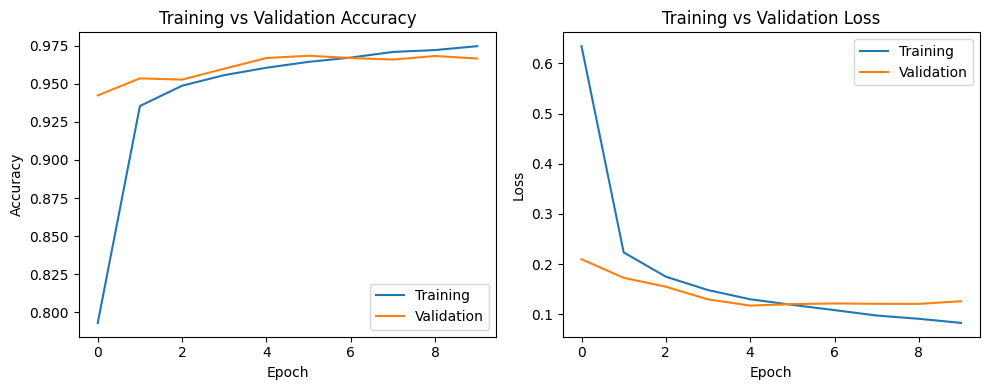

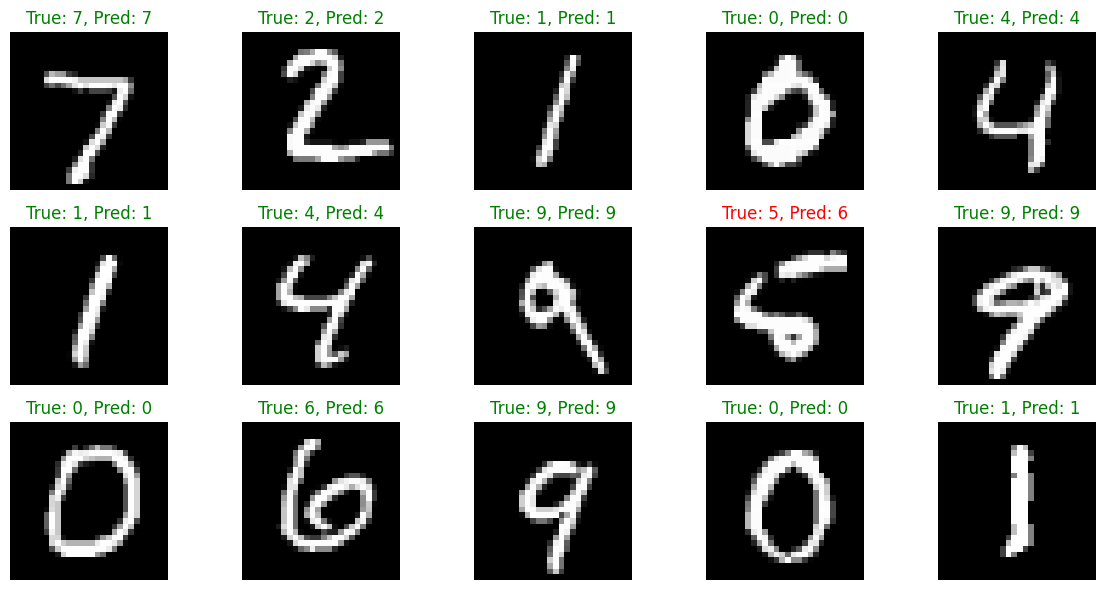

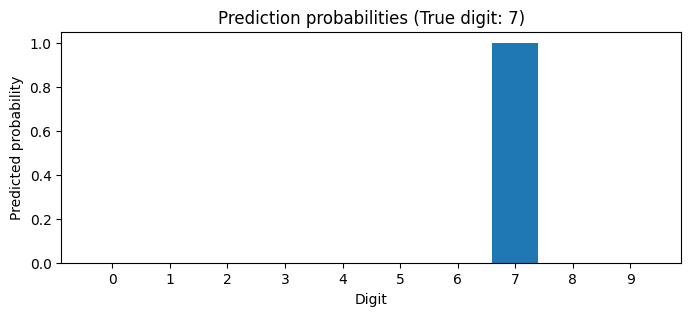

In [ ]:
# Install if needed:
# python -m pip install tensorflow matplotlib numpy

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

# 2. Normalize pixel values to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# 3. Create a deep neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, ),
    tf.keras.layers.Dense(64),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

# 4. Configure training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# 6. Evaluate on unseen test data
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)
print(f"Test accuracy: {test_accuracy:.4f}")

# 7. Visualize training and validation accuracy
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

# 8. Predict test images
probabilities = model.predict(X_test, verbose=0)
predictions = np.argmax(probabilities, axis=1)

# 9. Visualize predictions
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title(
        f"True: {y_test[i]}, Pred: {predictions[i]}",
        color="green" if y_test[i] == predictions[i] else "red"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

# 10. Show prediction probabilities for one image
idx = 0

plt.figure(figsize=(8, 3))
plt.bar(range(10), probabilities[idx])
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Predicted probability")
plt.title(f"Prediction probabilities (True digit: {y_test[idx]})")
plt.show()


In [ ]:
# if an LLM is producing 20,000 words i.e. 20000 probabilities. 
# How many neurons will be there in last layer? 20,000

In [ ]:
# https://chatgpt.com/share/6add8ad4-b260-83ea-8fcc-f70845e6126d